# Document AI — PDF 이해 / 계약서 / 영수증 / 표(Table) 분석

문서 이해 태스크는 텍스트 추출만으로는 놓치기 쉬운 **레이아웃 정보**가
핵심입니다. PDF는 페이지를 이미지로 렌더링해 VLM에 직접 입력합니다.

In [1]:
from vlm_utils import ask, ask_json, show

CONTRACT_PDF = "data/contract.pdf"
RECEIPT = "data/receipt.png"
TABLE = "data/table.png"

## PDF 이해
`pymupdf`(fitz)로 PDF 페이지를 이미지로 렌더링한 뒤 VLM에 전달합니다.

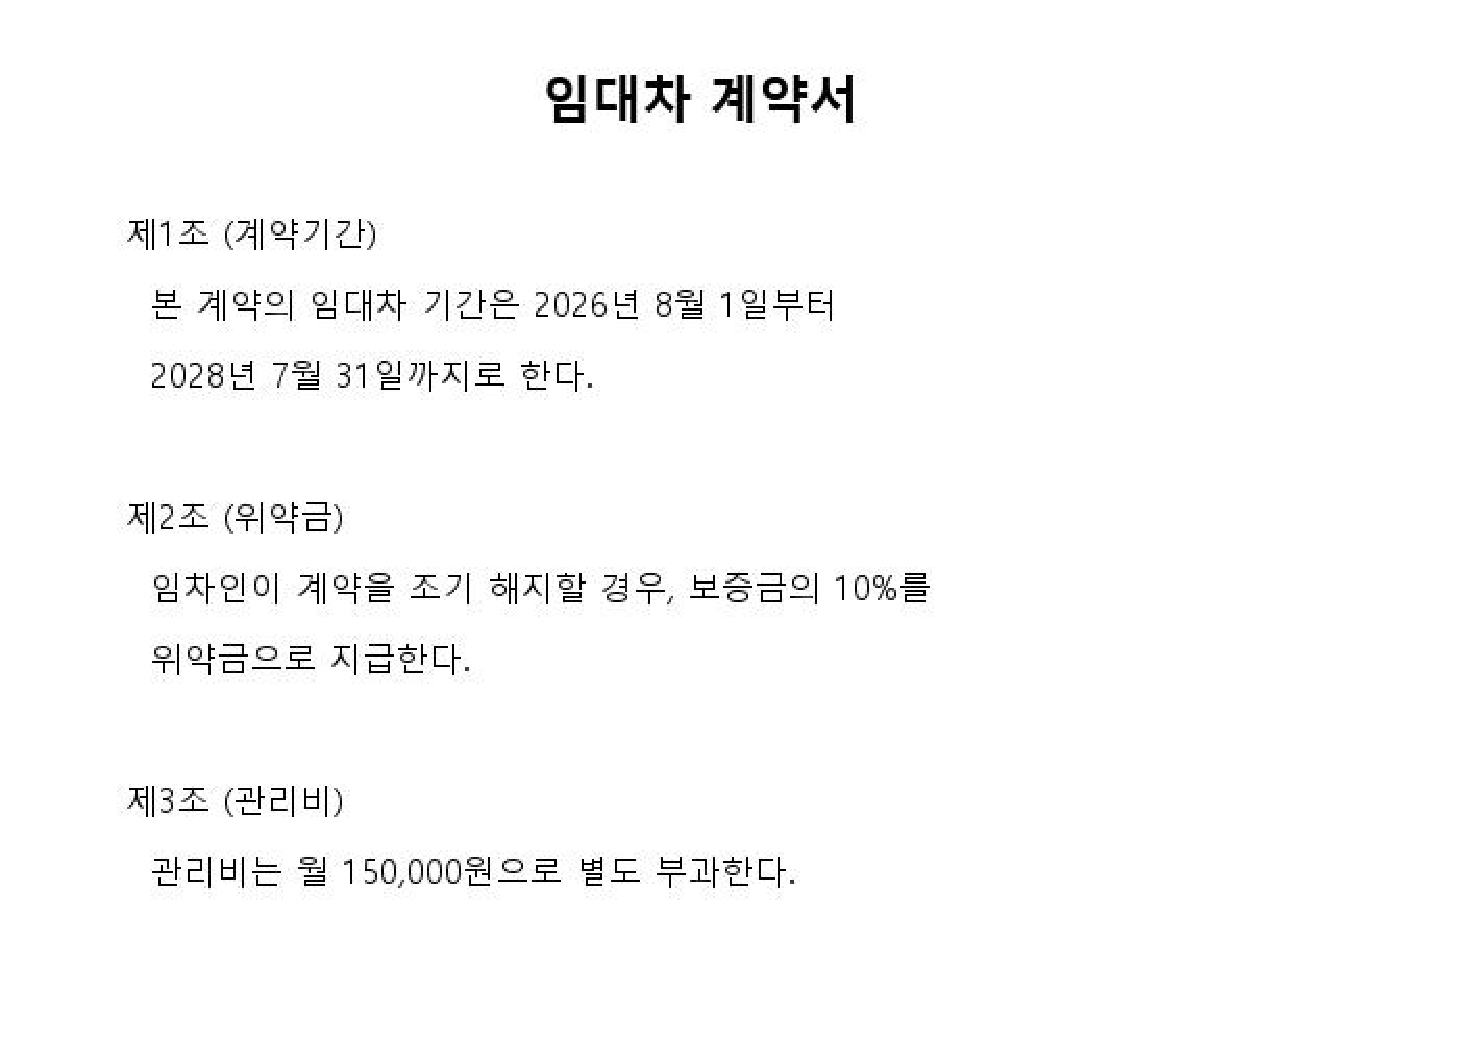

In [2]:
import fitz

doc = fitz.open(CONTRACT_PDF)
page = doc[0]
pix = page.get_pixmap(dpi=150)
contract_from_pdf = "data/_contract_page1.png"
pix.save(contract_from_pdf)
show(contract_from_pdf)

In [3]:
summary = ask(
    contract_from_pdf,
    "이 PDF 페이지의 핵심 내용을 3줄로 요약해줘.",
)
print(summary)

이 PDF 페이지는 임대차 계약서의 핵심 내용을 3절로 나뉘어 설명하고 있습니다.  
1. 계약 기간은 2026년 8월 1일부터 2028년 7월 31일까지이며, 임차인의 계약 조기 해지 가능성은 있음.  
2. 임차인은 계약 조기 해지 시 보증금의 10%를 위약금으로 지급해야 하며,  
3. 임대차 관리비는 월 150,000원으로 별도 부과됩니다.


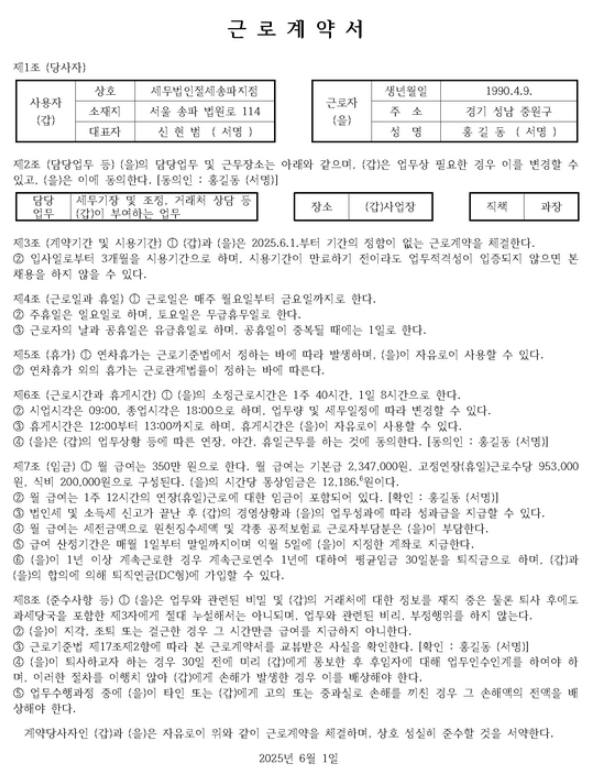

In [4]:
CONTRACT01 = "./data/contract01.png"
show(CONTRACT01)

In [5]:
summary = ask(
    CONTRACT01,
    "이 계약서의 사업자와 근로자 정보 알려줘."
    "이 계약서의 핵심 내용을 3줄로 요약해줘.",
)

print(summary)

**사업자 및 근로자 정보**

- **사업자**: 세무법인전세송파지점, 소재지 서울 송파 병원로 114, 대표자 신현범(서명).  
- **근로자**: 생년월일 1990.4.9., 주소 경기 성남 중원구, 성별 동(서명).

---

**핵심 내용 요약 (3줄)**

1. **계약 범위**: 2025년 6월 1일부터 3개월간 근로자(근로계약서)를 계약하고, 2025년 6월 1일부터 일정 기간 동안 근로계약을 체결하는 것으로, 사업자는 근로자의 업무를 일정 범위 내에서 수행하게 하고, 근로자는 업무에 따른 업무 수행을 할 예정이다.  
2. **업무 및 시간**: 근로자는 09:00~18:00 사이로 근무하며, 연차휴가는 근로기준법에 따라 정해지고, 근로자는 1일 8시간 내외로 근무하며, 1일 근로시간은 8시간 이상으로 제한하고, 근로자는 1일 8시간 이상 근무할 수 있다.  
3. **급여 및 협약 조건**: 350만 원의 월급을 받으며, 근로자는 계약기간 동안 근로자(근로자)를 일정 기간 동안 사용하고, 근로자(근로자)는 계약기간 동안 근로자(근로자)에게 계약기간 동안 근로자(근로자)를 사용할 수 있으며, 근로자는 근로자(근로자)에게 계약기간 동안 근로자(근로자)를 사용할 수 있으며, 근로자는 근로자(근로자)에게 계약기간 동안 근로자(근로자)를 사용할 수 있으며, 근로자는 근로자(근로자)에게 계약기간 동안 근로자(근로자)를 사용할 수 있으며, 근로자는 근로자(근로자)에게 계약기간 동안 근로자(근로자)를 사용할 수 있으며, 근로자는 근로자(근로자)에게 계약기간 동안 근로자(근로자)를 사용할 수 있으며, 근로자는 근로자(근로자)에게 계약기간 동안 근로자(근로자)를 사용할 수 있으며, 근로자는 근로자(근로자)에게 계약기간 동안 근로자(근로자)를 사용할 수 있으며, 근로자는 근로자(근로자)에게 계약기간 동안 근로자(근로자)를 사용할 수 있으며, 근로자는 근로자(근로자)에게 계약기간 동안 근로자(근로자)를 사용할 수 있으며, 근로자는 근로자(근로자)에게 계약기간 동

## 계약서 분석
정확도가 중요한 도메인이므로 **원문 문구를 그대로 인용**하도록 요청해
검증 가능한 답변을 받습니다.

In [6]:
contract_qa = ask(
    contract_from_pdf,
    "이 계약서 이미지에서 계약 기간과 위약금 조항을 찾아, 관련 원문 문장을 "
    "그대로 인용한 뒤 요약해줘. 해당 조항이 없으면 '명시되어 있지 않음'이라고 답해.",
)

print(contract_qa)

**계약 기간 관련 문장 (제1조):**  
본 계약의 임대차 기간은 2026년 8월 1일부터 2028년 7월 31일까지로 한다.

**위약금 관련 문장 (제2조):**  
임차인이 계약을 조기 해지할 경우, 보증금의 10%를 위약금으로 지급한다.

---

**요약:**  
- **계약 기간**: 2026년 8월 1일부터 2028년 7월 31일까지.  
- **위약금**: 계약 조기 해지 시 보증금의 10%를 지급.


In [7]:
contract_qa = ask(
    CONTRACT01,
    "이 계약서 이미지에서 계약 기간과 위약금 조항을 찾아, 관련 원문 문장을 "
    "그대로 인용한 뒤 요약해줘. 해당 조항이 없으면 '명시되어 있지 않음'이라고 답해.",
)

print(contract_qa)

### 계약 기간

**원문 문장 (제3조 ①):**  
**(갑)과 (을)은 2025.6.1.부터 기간의 정량이 있는 근로계약을 체결한다.**

**요약:**  
근로계약의 시작일은 2025년 6월 1일이며, 계약 기간은 정확히 기정된 기간이 있다(단, 정확한 종료일은 이미지에서 명시되어 있지 않음).

---

### 위약금 조항

**원문 문장 (제5조 ②):**  
**“**(을)은 (갑)의 업무상황 등에 따른 연장, 아군, 휴일근무를 하는 것에 동의한다.”**

**요약:**  
위약금은 명시되어 있지 않음. 이 조항은 업무상황에 따른 연장, 휴일근무 등의 동의를 요구하지만, 위약금의 구체적 조건(예: 계약 해지 시 발생하는 금전적 책임)은 언급되지 않음.

또한, **제6조 ④**에 따르면, (을)은 (갑)의 업무상황 등에 대해 동의하는 것으로, 위약금에 대한 규정은 이 조항에서 별도로 언급되지 않음.

따라서, **위약금 조항은 명시되어 있지 않음.**

---

**결론:**

- **계약 기간:** “2025.6.1.부터 기간의 정량이 있는 근로계약을 체결한다.” → 시작일은 2025.6.1일이며, 정확한 종료일은 명시되지 않음.
- **위약금:** 명시되어 있지 않음.


## 영수증 분석 — 구조화 추출
상호명, 날짜, 품목, 총액을 JSON 스키마로 한 번에 추출합니다.

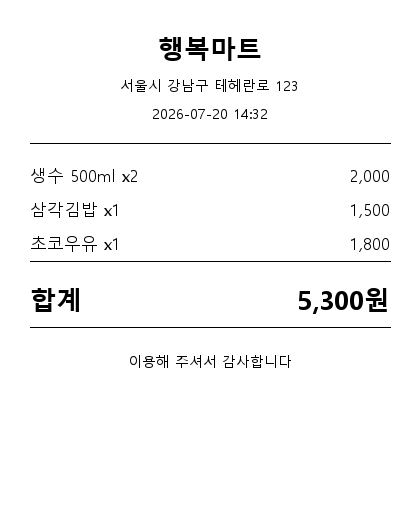

{'store': '서울시 강남구 테헤란로 123', 'date': '2026-07-20', 'items': [{'name': '생수 500ml', 'qty': 2, 'price': 2000}, {'name': '삼각김밥', 'qty': 1, 'price': 1500}, {'name': '초코우유', 'qty': 1, 'price': 1800}], 'total': 5300}


In [8]:
show(RECEIPT)
receipt_schema = '''
아래 JSON 스키마로만 답해.
{
  "store": "string",
  "date": "YYYY-MM-DD",
  "items": [{"name": "string", "qty": "number", "price": "number"}],
  "total": "number"
}
'''
receipt_json = ask_json(RECEIPT, receipt_schema)
print(receipt_json)

assert receipt_json["total"] == 5300

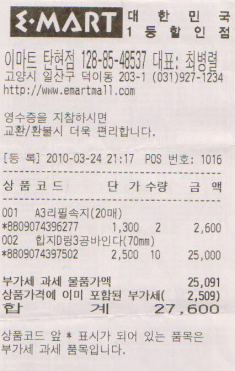

In [9]:
RECEIPT01 = "./data/receipt01.png"
show(RECEIPT01)

In [10]:
receipt_schema = '''
아래 JSON 스키마로만 답해.
{
  "store": "string",
  "date": "YYYY-MM-DD",
  "items": [{"name": "string", "qty": "number", "price": "number"}],
  "total": "number"
}
'''
receipt_json = ask_json(RECEIPT01, receipt_schema)
print(receipt_json)

assert receipt_json["total"] == 27600

{'store': 'E-MART', 'date': '2010-03-24', 'items': [{'name': 'A3리필속지(20매)', 'qty': 2, 'price': 2600}, {'name': '흰지D림3공바인다(70mm)', 'qty': 10, 'price': 25000}], 'total': 27600}


## 표(Table) 분석
표는 "행-열 관계"가 핵심이므로, **마크다운 표 형식으로 그대로 옮겨 적게** 하면
구조가 잘 보존됐는지 눈으로 바로 확인할 수 있습니다.

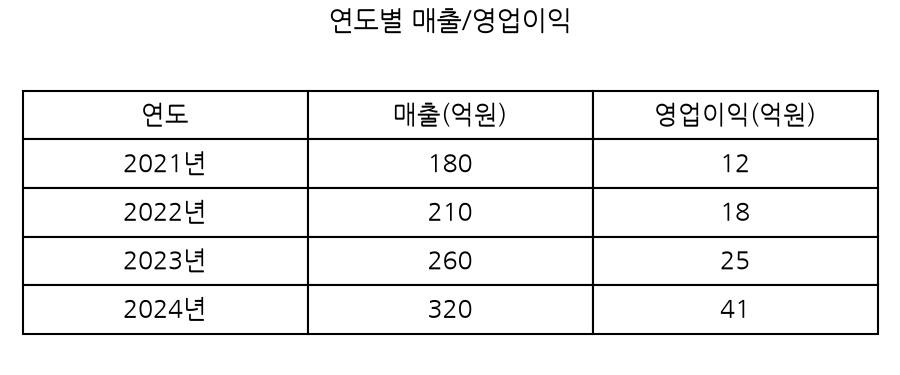

In [11]:
show(TABLE)

In [12]:
table_qa = ask(TABLE, "이 표에서 '매출(억원)' 열의 값이 가장 큰 연도를 알려줘.")

print(table_qa)

표에서 '매출(억원)' 열의 값이 가장 큰 연도는 **2024년**입니다.

**해설:**  
- 2021년: 180억원  
- 2022년: 210억원  
- 2023년: 260억원  
- 2024년: **320억원** ← 가장 큰 값

따라서, **2024년**이 답입니다.


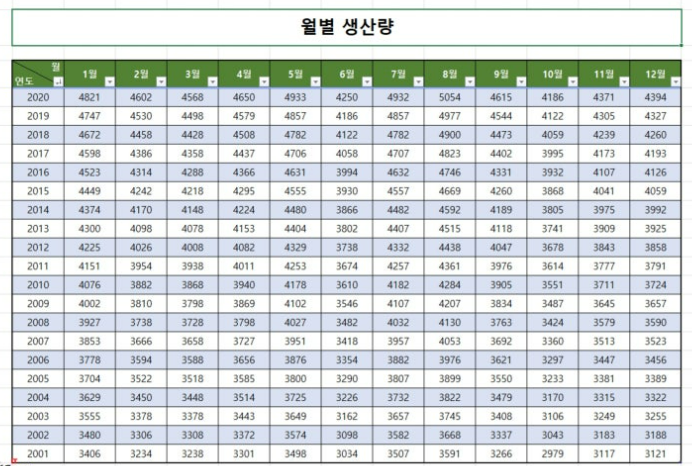

In [13]:
TABLE01 = "./data/table01.png"
show(TABLE01)

In [14]:
table_qa = ask(TABLE01, "이 표에서 연도별 가장 생산량이 높은 월 알려줘.")

print(table_qa)

이 표에서 **각 연도별 가장 높은 생산량을 가진 월**을 찾기 위해, 각 연도의 12개 월 중 가장 큰 수를 확인해보겠습니다.

---

### **2020년**
- 1월: 4821 → **최고**
- 2월: 4602
- 3월: 4568
- 4월: 4650
- 5월: 4933
- 6월: 4250
- 7월: 4932
- 8월: 5054 → **최고**
- 9월: 4615
- 10월: 4186
- 11월: 4371
- 12월: 4394

👉 **2020년: 8월 (5054)**

---

### **2019년**
- 최대값: **4977 (8월)**

---

### **2018년**
- 최대값: **4900 (8월)**

---

### **2017년**
- 최대값: **4823 (8월)**

---

### **2016년**
- 최대값: **4746 (8월)**

---

### **2015년**
- 최대값: **4669 (8월)**

---

### **2014년**
- 최대값: **4592 (8월)**

---

### **2013년**
- 최대값: **4515 (8월)**

---

### **2012년**
- 최대값: **4438 (8월)**

---

### **2011년**
- 최대값: **4361 (8월)**

---

### **2010년**
- 최대값: **4284 (8월)**

---

### **2009년**
- 최대값: **4207 (8월)**

---

### **2008년**
- 최대값: **4130 (8월)**

---

### **2007년**
- 최대값: **4053 (8월)**

---

### **2006년**
- 최대값: **3976 (8월)**

---

### **2005년**
- 최대값: **3899 (8월)**

---

### **2004년**
- 최대값: **3822 (8월)**

---

### **2003년**
- 최대값: **3745 (8월)**

---

### **2002년**
- 최대값: **3668 